In [5]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from collections import deque

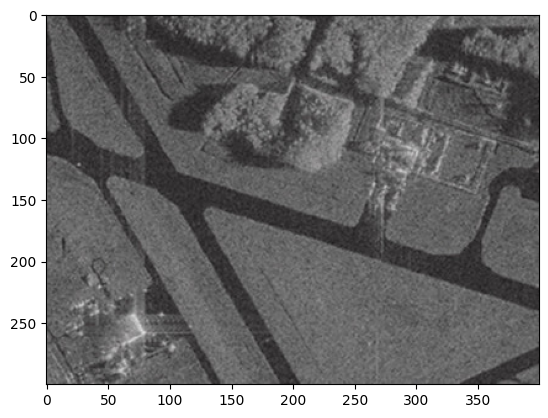

In [6]:
image = cv2.imread('sar_4.jpg')
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image_rgb)
plt.show()

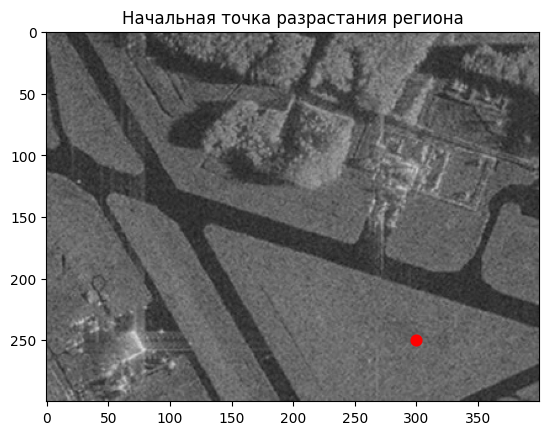

Яркость начальной точки: 72


In [7]:
## Выбор начальной точки для разрастания региона

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

seed_x = 300
seed_y = 250

seed_value = int(gray[seed_y, seed_x])

plt.imshow(gray, cmap='gray', vmin=0, vmax=255)
plt.scatter(seed_x, seed_y, c='red', s=60)
plt.title('Начальная точка разрастания региона')
plt.show()

print('Яркость начальной точки:', seed_value)

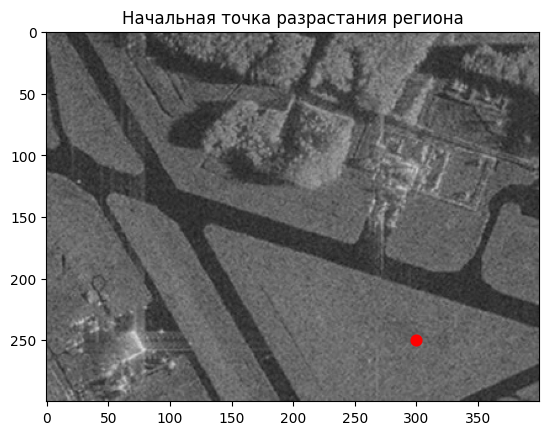

Яркость начальной точки: 72


In [8]:
## Выбор начальной точки для разрастания региона

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

seed_x = 300
seed_y = 250

seed_value = int(gray[seed_y, seed_x])

plt.imshow(gray, cmap='gray', vmin=0, vmax=255)
plt.scatter(seed_x, seed_y, c='red', s=60)
plt.title('Начальная точка разрастания региона')
plt.show()

print('Яркость начальной точки:', seed_value)

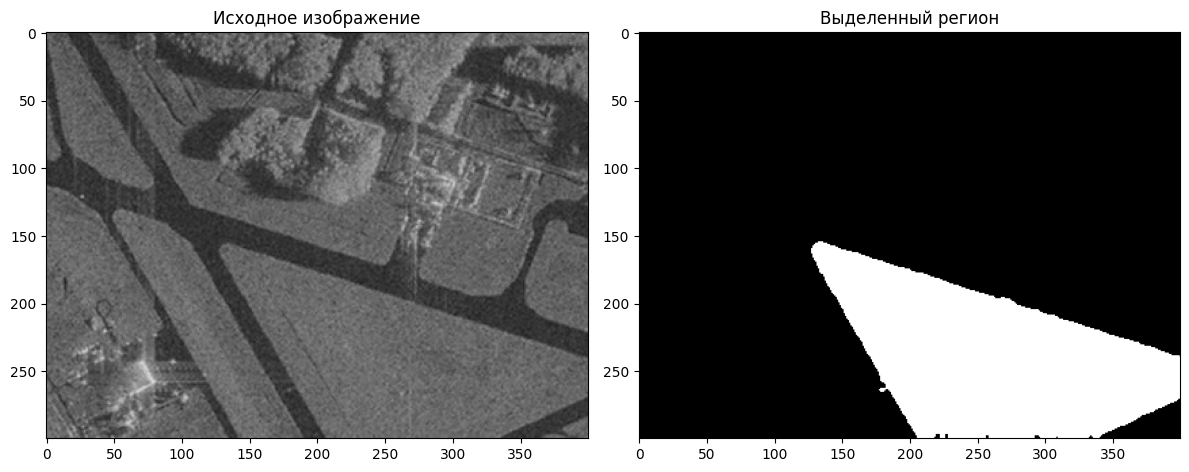

Количество выделенных пикселей: 22115


In [9]:
## Разрастание региона по яркости

threshold = 22

gray_smooth = cv2.GaussianBlur(gray, (7, 7), 0)
seed_value = int(gray_smooth[seed_y, seed_x])

height, width = gray_smooth.shape
region_mask = np.zeros((height, width), dtype=np.uint8)

queue = deque([(seed_y, seed_x)])
region_mask[seed_y, seed_x] = 255

while queue:
    y, x = queue.popleft()

    for dy, dx in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        ny, nx = y + dy, x + dx

        if 0 <= ny < height and 0 <= nx < width:
            if region_mask[ny, nx] == 0:
                if abs(int(gray_smooth[ny, nx]) - seed_value) <= threshold:
                    region_mask[ny, nx] = 255
                    queue.append((ny, nx))

## Заполнение пропусков внутри выделенного региона

contours, _ = cv2.findContours(
    region_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

region_filled = np.zeros_like(region_mask)

cv2.drawContours(
    region_filled,
    contours,
    -1,
    255,
    cv2.FILLED
)

region_mask = region_filled


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение')

plt.subplot(1, 2, 2)
plt.imshow(region_mask, cmap='gray', vmin=0, vmax=255)
plt.title('Выделенный регион')

plt.tight_layout()
plt.show()

print('Количество выделенных пикселей:', np.count_nonzero(region_mask))

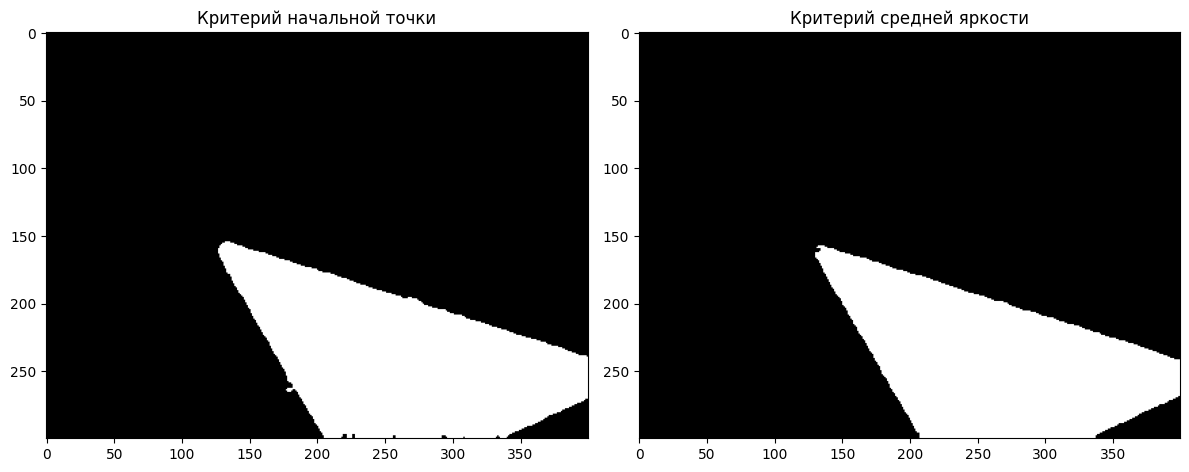

Начальная точка: 22115 пикселей
Средняя яркость: 20969 пикселей


In [10]:
## Разрастание региона по средней яркости

threshold_mean = 12

region_mean_mask = np.zeros((height, width), dtype=np.uint8)

queue = deque([(seed_y, seed_x)])
region_mean_mask[seed_y, seed_x] = 255

region_sum = float(gray_smooth[seed_y, seed_x])
region_count = 1

while queue:
    y, x = queue.popleft()

    for dy, dx in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        ny, nx = y + dy, x + dx

        if 0 <= ny < height and 0 <= nx < width:
            if region_mean_mask[ny, nx] == 0:

                region_mean = region_sum / region_count

                pixel_value = float(gray_smooth[ny, nx])

                if abs(pixel_value - region_mean) <= threshold_mean:
                    region_mean_mask[ny, nx] = 255
                    queue.append((ny, nx))

                    region_sum += pixel_value
                    region_count += 1

## Заполнение пропусков второго региона

contours_mean, _ = cv2.findContours(
    region_mean_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

region_mean_filled = np.zeros_like(region_mean_mask)

cv2.drawContours(
    region_mean_filled,
    contours_mean,
    -1,
    255,
    cv2.FILLED
)

region_mean_mask = region_mean_filled


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(region_mask, cmap='gray', vmin=0, vmax=255)
plt.title('Критерий начальной точки')

plt.subplot(1, 2, 2)
plt.imshow(region_mean_mask, cmap='gray', vmin=0, vmax=255)
plt.title('Критерий средней яркости')

plt.tight_layout()
plt.show()

print('Начальная точка:', np.count_nonzero(region_mask), 'пикселей')
print('Средняя яркость:', np.count_nonzero(region_mean_mask), 'пикселей')

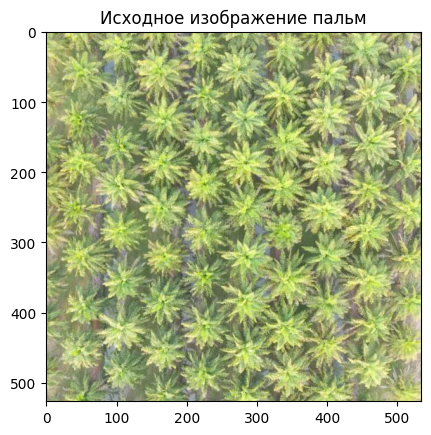

In [11]:
palm_image = cv2.imread('palm_1.JPG')
palm_rgb = cv2.cvtColor(palm_image, cv2.COLOR_BGR2RGB)

plt.imshow(palm_rgb)
plt.title('Исходное изображение пальм')
plt.show()

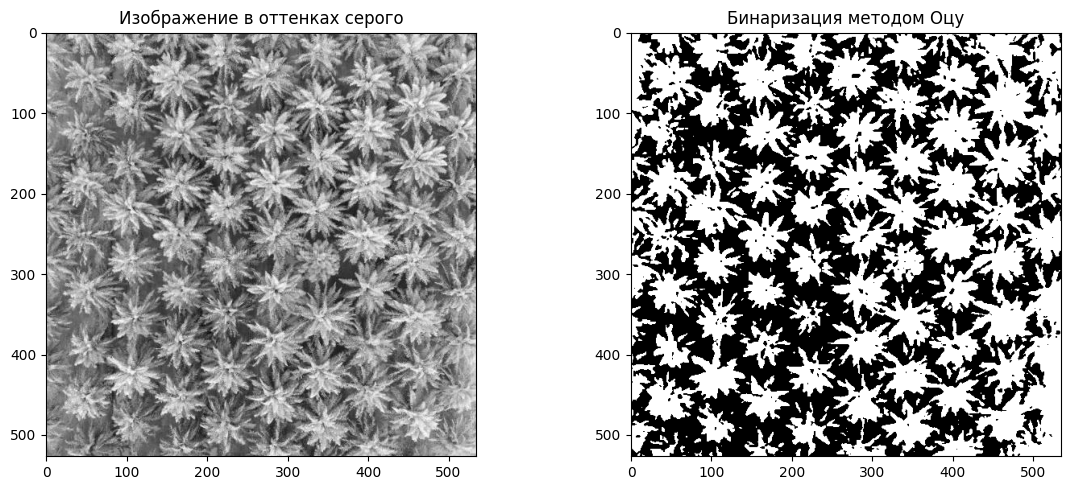

In [12]:
## Бинаризация изображения пальм

palm_gray = cv2.cvtColor(palm_image, cv2.COLOR_BGR2GRAY)

palm_blur = cv2.GaussianBlur(palm_gray, (5, 5), 0)

_, palm_binary = cv2.threshold(
    palm_blur, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(palm_gray, cmap='gray')
plt.title('Изображение в оттенках серого')

plt.subplot(1, 2, 2)
plt.imshow(palm_binary, cmap='gray')
plt.title('Бинаризация методом Оцу')

plt.tight_layout()
plt.show()

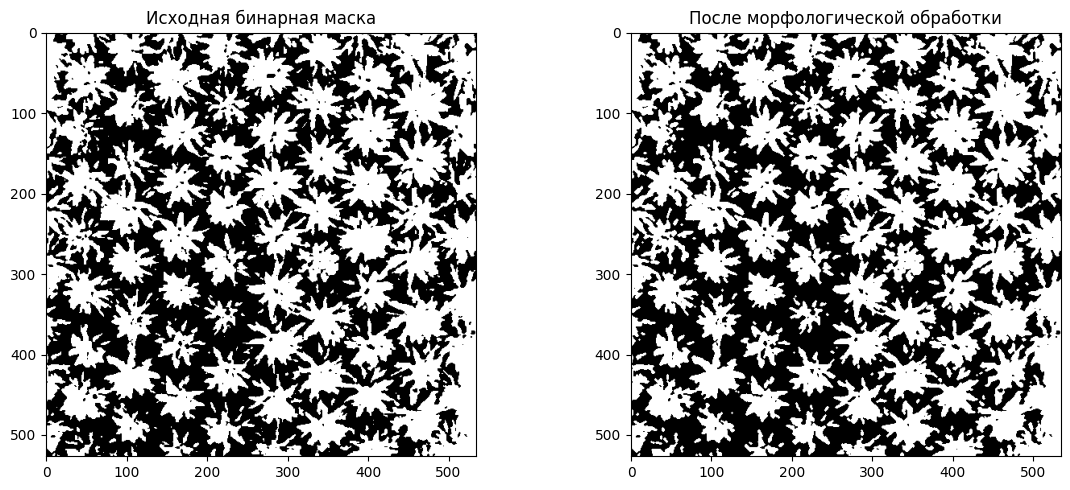

In [13]:
## Подготовка бинарной маски

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

palm_clean = cv2.morphologyEx(
    palm_binary,
    cv2.MORPH_OPEN,
    kernel
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(palm_binary, cmap='gray', vmin=0, vmax=255)
plt.title('Исходная бинарная маска')

plt.subplot(1, 2, 2)
plt.imshow(palm_clean, cmap='gray', vmin=0, vmax=255)
plt.title('После морфологической обработки')

plt.tight_layout()
plt.show()

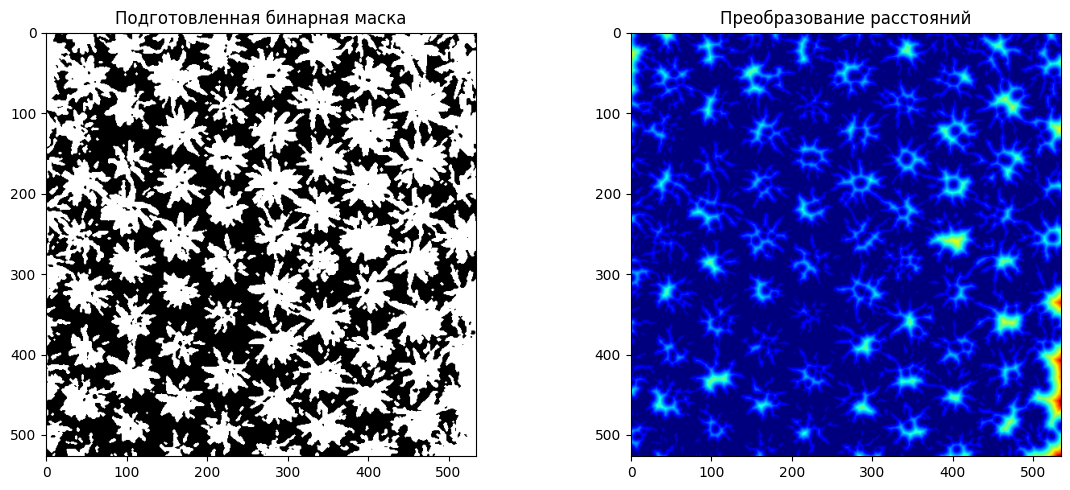

Максимальное расстояние: 27.17


In [14]:
## Преобразование расстояний (Distance Transform)

dist_transform = cv2.distanceTransform(
    palm_clean, cv2.DIST_L2, 5
)

dist_normalized = cv2.normalize(
    dist_transform, None, 0, 1, cv2.NORM_MINMAX
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(palm_clean, cmap='gray', vmin=0, vmax=255)
plt.title('Подготовленная бинарная маска')

plt.subplot(1, 2, 2)
plt.imshow(dist_normalized, cmap='jet')
plt.title('Преобразование расстояний')

plt.tight_layout()
plt.show()

print('Максимальное расстояние:', round(dist_transform.max(), 2))

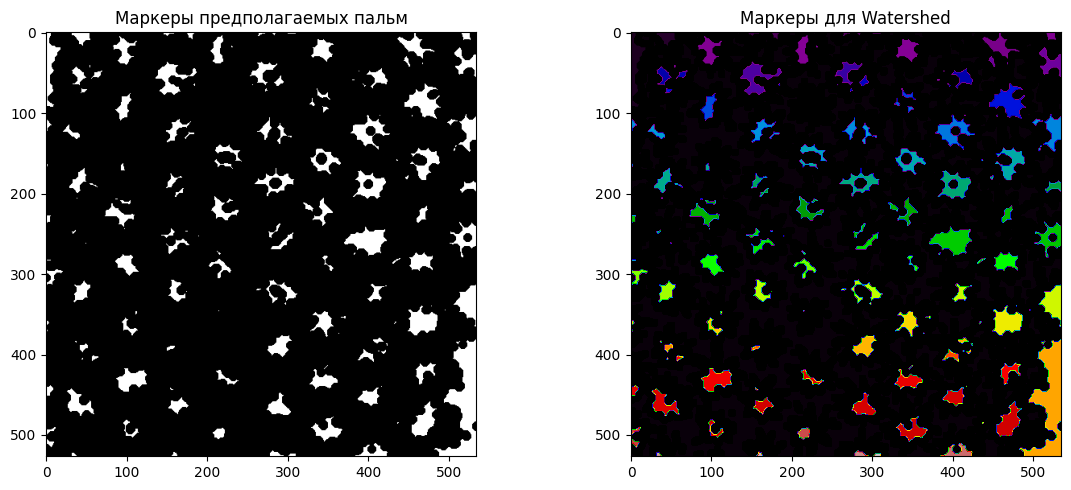

Количество областей-маркеров: 153


In [15]:
## Создание маркеров для Watershed

_, sure_fg = cv2.threshold(
    dist_transform,
    0.2 * dist_transform.max(),
    255,
    cv2.THRESH_BINARY
)

sure_fg = np.uint8(sure_fg)

kernel = np.ones((3, 3), np.uint8)

sure_bg = cv2.dilate(palm_clean, kernel, iterations=3)

unknown = cv2.subtract(sure_bg, sure_fg)

num_labels, markers = cv2.connectedComponents(sure_fg)

markers = markers + 1
markers[unknown == 255] = 0

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(sure_fg, cmap='gray')
plt.title('Маркеры предполагаемых пальм')

plt.subplot(1, 2, 2)
plt.imshow(markers, cmap='nipy_spectral')
plt.title('Маркеры для Watershed')

plt.tight_layout()
plt.show()

print('Количество областей-маркеров:', num_labels - 1)

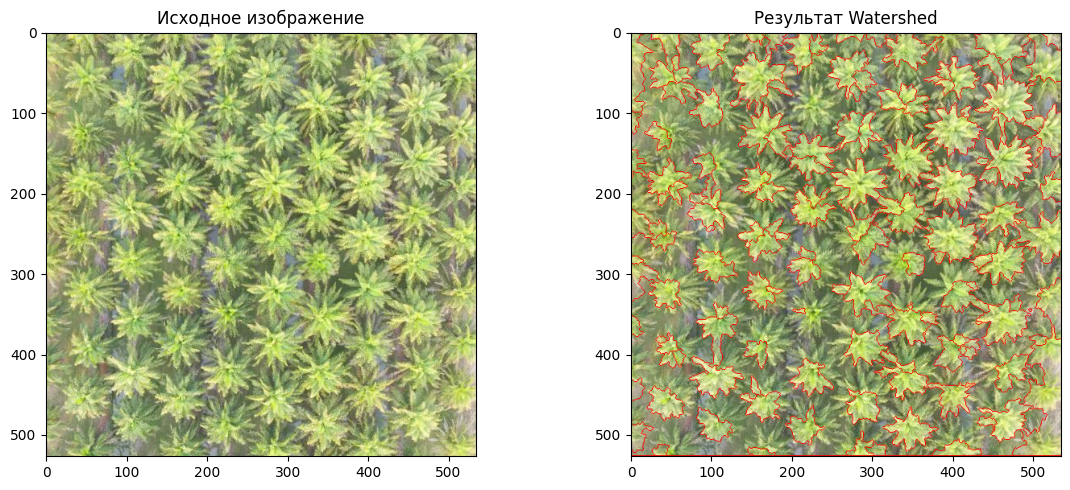

Количество обнаруженных пальм: 149


In [16]:
## Сегментация Watershed и подсчет пальм

watershed_markers = markers.copy()

cv2.watershed(palm_image, watershed_markers)

palm_result = palm_rgb.copy()

palm_result[watershed_markers == -1] = [255, 0, 0]

palm_count = len(np.unique(watershed_markers[watershed_markers > 1]))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(palm_rgb)
plt.title('Исходное изображение')

plt.subplot(1, 2, 2)
plt.imshow(palm_result)
plt.title('Результат Watershed')

plt.tight_layout()
plt.show()

print('Количество обнаруженных пальм:', palm_count)